# AI Model Experiment & Evaluation
**Eksperimen Perbandingan Klasifikasi Sentimen: Model Klasik (Scikit-learn) vs LLM API (Gemini)**

Notebook ini membandingkan dua pendekatan AI untuk mengklasifikasikan sentimen ulasan pelanggan e-commerce (`positif`/`negatif`):
1. Model klasik Machine Learning (Scikit-learn dengan TF-IDF)
2. LLM API (Gemini `gemini-3.5-flash-lite` dengan zero-shot prompting)

Kedua pendekatan dievaluasi di atas **test set yang sama persis** tanpa data leakage agar perbandingan berlangsung adil dan dapat direproduksi.

> 🔧 **Catatan Konfigurasi Dataset & Reproducibility**
>
> - Dataset: `data/customer_reviews_sentiment.csv` dengan kolom fitur `review_text` dan label `sentiment` (`positif`/`negatif`).
> - Random seed konsisten: `RANDOM_STATE = 42`.
> - Strategi split: `GroupShuffleSplit` berdasarkan `review_text` agar tidak ada teks ulasan identik yang bocor ke training set dan test set sekaligus.

## 1. Problem Statement

- **Objective**: Membangun dan mengevaluasi dua kandidat pendekatan klasifikasi sentimen otomatis untuk ulasan pelanggan pada halaman produk e-commerce, lalu memberikan rekomendasi berbasis data untuk sistem produksi.
- **Task & Target**: Klasifikasi teks biner (*binary text classification*) pada kolom `review_text` menuju label `sentiment` (`positif` atau `negatif`).
- **Kandidat Pendekatan**:
  1. **Model Klasik (Scikit-learn)**: Ekstraksi fitur `TfidfVectorizer` + seleksi kandidat model linear/probabilistik (`LogisticRegression`, `LinearSVC`, `MultinomialNB`) di training set.
  2. **LLM API (Gemini)**: Zero-shot classification menggunakan `gemini-3.5-flash-lite` tanpa proses training konvensional.
- **Batasan & Asumsi**:
  - Evaluasi wajib memakai test set dan ground-truth label yang identik.
  - Tidak boleh ada data leakage dari test set ke proses training, seleksi model, maupun prompt LLM.
  - Waktu training/inference, stabilitas format output, rate limit, dan estimasi biaya operasional diukur/dianalisis langsung dari hasil eksekusi.

## 2. Import Library & Load Dataset

In [1]:
import os
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from google import genai
from google.genai import types

RANDOM_STATE = 42
LABELS = ['negatif', 'positif']

# Resolve project root robustly whether executed from notebook/ or repo root
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_PATH = BASE_DIR / 'data' / 'customer_reviews_sentiment.csv'
RESULTS_DIR = BASE_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

load_dotenv(BASE_DIR / '.env')

df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
df.head(10)

Dataset shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif
5,6,Sepatu Sneakers,"Packing rapi, produk sesuai deskripsi. Recomme...",positif
6,7,Powerbank,Sudah bayar mahal tapi kualitas jauh dari eksp...,negatif
7,8,Lampu LED,"Belanja disini selalu puas, kualitas terjaga.",positif
8,9,Botol Minum,"Bahan nyaman dipakai, ukuran pas, tidak mengec...",positif
9,10,Kaos Polos,"Bahan nyaman dipakai, ukuran pas, tidak mengec...",positif


In [2]:
# Initial data inspection: schema, missing values, duplicates, and label consistency
print('=== Info & Tipe Data ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\nTotal exact duplicate rows:', df.duplicated().sum())
print('Unique review_id:', df['review_id'].nunique())
print('Unique product_name:', df['product_name'].nunique())
print('Unique review_text:', df['review_text'].nunique())

label_per_text = df.groupby('review_text')['sentiment'].nunique()
print('Texts with conflicting sentiment labels:', int((label_per_text > 1).sum()))

print('\n=== Distribusi Label Sentimen ===')
dist_df = pd.DataFrame({
    'count': df['sentiment'].value_counts(),
    'proportion': df['sentiment'].value_counts(normalize=True).round(4),
})
print(dist_df)

word_counts = df['review_text'].str.split().str.len()
print(f'\nReview word length -> min: {word_counts.min()}, median: {word_counts.median():.1f}, max: {word_counts.max()}')
print('\nTop 10 repeated review texts:')
print(df['review_text'].value_counts().head(10))

=== Info & Tipe Data ===
review_id       int64
product_name      str
review_text       str
sentiment         str
dtype: object

=== Missing Values ===
review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64

Total exact duplicate rows: 0
Unique review_id: 200
Unique product_name: 15
Unique review_text: 40
Texts with conflicting sentiment labels: 0

=== Distribusi Label Sentimen ===
           count  proportion
sentiment                   
positif      110        0.55
negatif       90        0.45

Review word length -> min: 6, median: 8.0, max: 11

Top 10 repeated review texts:
review_text
Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.                      12
Produknya rapi dan bersih, tidak ada cacat sama sekali.                     9
Pengiriman lambat sekali, sudah dua minggu belum sampai.                    8
Kualitas produk jelek, baru dipakai sekali sudah rusak.                     8
Pelayanan ramah dan responsif, barang sampai lebih cepat dari e

**Temuan Pemeriksaan Awal Dataset:**
- Dataset terdiri dari 200 baris dan 4 kolom (`review_id`, `product_name`, `review_text`, `sentiment`) tanpa missing value maupun baris duplikat penuh.
- Fitur teks yang digunakan adalah `review_text` dan label target adalah `sentiment` (`positif`: 110 / 55%, `negatif`: 90 / 45%).
- **Temuan kritis**: dari 200 baris, hanya terdapat **40 teks ulasan unik** (`review_text`), masing-masing berulang 1–12 kali di berbagai produk tanpa label yang bertentangan. Jika menggunakan `train_test_split` acak biasa, teks yang sama persis akan muncul di training set dan test set (data leakage / memorisasi).

## 3. Menyiapkan Train/Test Split

Untuk mencegah *exact-text data leakage* akibat 40 teks unik yang berulang di 200 baris, pembagian data dilakukan menggunakan `GroupShuffleSplit` dengan `groups=df['review_text']`, `test_size=0.2`, dan `random_state=42`. Dengan cara ini:
- Ukuran split tetap mendekati 80/20.
- Seluruh kemunculan sebuah `review_text` berada eksklusif di train atau test set (0 overlap).
- **Test set yang sama persis** (`X_test`, `y_test`) dikunci untuk mengevaluasi Scikit-learn dan Gemini API.

In [3]:
X = df['review_text']
y = df['sentiment']
groups = df['review_text']

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train = X.iloc[train_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
test_meta = df.iloc[test_idx][['review_id', 'product_name', 'review_text', 'sentiment']].reset_index(drop=True)

# Verify zero text overlap between train and test sets
overlap_texts = set(X_train) & set(X_test)
assert len(overlap_texts) == 0, f'Leakage detected: {len(overlap_texts)} overlapping texts'

print(f'Train size: {len(X_train)} rows ({X_train.nunique()} unique texts)')
print(f'Test size : {len(X_test)} rows ({X_test.nunique()} unique texts)')
print(f'Text overlap between train & test: {len(overlap_texts)}')
print('\nTrain label distribution:\n', y_train.value_counts())
print('\nTest label distribution:\n', y_test.value_counts())

Train size: 159 rows (32 unique texts)
Test size : 41 rows (8 unique texts)
Text overlap between train & test: 0

Train label distribution:
 sentiment
positif    83
negatif    76
Name: count, dtype: int64

Test label distribution:
 sentiment
positif    27
negatif    14
Name: count, dtype: int64


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

Konfigurasi preprocessing dan representasi teks:
- `clean_text`: mengubah teks ke huruf kecil (*lowercase*), menghapus karakter non-alfanumerik (tanda baca/simbol) menjadi spasi, dan menormalkan spasi ganda.
- **Catatan desain**: kata negasi Bahasa Indonesia (`tidak`, `bukan`, `kurang`, `jangan`) dipertahankan (tidak memakai stopword removal agresif) karena negasi membalik polaritas sentimen.
- **TF-IDF Configuration**:
  - `preprocessor=clean_text`
  - `ngram_range=(1, 2)` untuk menangkap unigram serta frasa bigram negasi seperti `"tidak sesuai"`, `"tidak responsif"`, `"sangat puas"`.
  - `sublinear_tf=True` untuk meredam dominasi kata berfrekuensi tinggi.
  - `min_df=1` karena korpus training hanya terdiri dari 32 teks unik.

In [4]:
def clean_text(text: str) -> str:
    """Normalize review text while preserving negation words critical for sentiment."""
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

TFIDF_PARAMS = {
    'preprocessor': clean_text,
    'ngram_range': (1, 2),
    'min_df': 1,
    'sublinear_tf': True,
}

print('Contoh hasil preprocessing:')
for sample in X_train.drop_duplicates().head(3):
    print(f'  Raw  : {sample}')
    print(f'  Clean: {clean_text(sample)}')

Contoh hasil preprocessing:
  Raw  : Terima kasih seller, barangnya awet dan sesuai deskripsi.
  Clean: terima kasih seller barangnya awet dan sesuai deskripsi
  Raw  : Warna produk berbeda jauh dari foto di listing.
  Clean: warna produk berbeda jauh dari foto di listing
  Raw  : Packing rapi, produk sesuai deskripsi. Recommended seller!
  Clean: packing rapi produk sesuai deskripsi recommended seller


### 4.2 Training Model & Seleksi Kandidat (GroupKFold CV)

Agar seleksi model bebas dari data leakage dan tidak menyentuh test set, tiga algoritma klasik dibandingkan di training set menggunakan **5-fold `GroupKFold`** (dikelompokkan berdasarkan `review_text`):
1. `LogisticRegression(C=1.0, max_iter=1000, random_state=42)`
2. `LinearSVC(C=1.0, random_state=42)`
3. `MultinomialNB(alpha=1.0)`

In [5]:
candidates = {
    'LogisticRegression': LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
    'LinearSVC': LinearSVC(C=1.0, random_state=RANDOM_STATE),
    'MultinomialNB': MultinomialNB(alpha=1.0),
}

gkf = GroupKFold(n_splits=5)
cv_rows = []

for name, estimator in candidates.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('clf', estimator),
    ])
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=gkf,
        groups=X_train,
        scoring=['accuracy', 'f1_weighted', 'f1_macro'],
    )
    cv_rows.append({
        'model': name,
        'cv_accuracy_mean': scores['test_accuracy'].mean(),
        'cv_f1_weighted_mean': scores['test_f1_weighted'].mean(),
        'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values(
    by=['cv_f1_weighted_mean', 'cv_accuracy_mean'], ascending=False
).reset_index(drop=True)
print('=== Hasil 5-Fold GroupKFold Cross-Validation (Training Set) ===')
print(cv_results_df.to_string(index=False))

best_model_name = cv_results_df.loc[0, 'model']
print(f'\nModel klasik terpilih: {best_model_name}')

best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf', candidates[best_model_name]),
])

t0 = time.perf_counter()
best_pipeline.fit(X_train, y_train)
classic_train_time_sec = time.perf_counter() - t0
vocab_size = len(best_pipeline.named_steps['tfidf'].vocabulary_)
print(f'Training selesai dalam {classic_train_time_sec:.6f} detik | Ukuran vocabulary TF-IDF: {vocab_size} fitur')

=== Hasil 5-Fold GroupKFold Cross-Validation (Training Set) ===
             model  cv_accuracy_mean  cv_f1_weighted_mean  cv_f1_macro_mean
         LinearSVC          0.653629             0.647914          0.651758
     MultinomialNB          0.597379             0.594003          0.587046
LogisticRegression          0.546573             0.502600          0.535077

Model klasik terpilih: LinearSVC
Training selesai dalam 0.012088 detik | Ukuran vocabulary TF-IDF: 338 fitur


### 4.3 Prediksi pada Test Set

In [6]:
t0 = time.perf_counter()
y_pred_classic = best_pipeline.predict(X_test)
classic_infer_time_sec = time.perf_counter() - t0
classic_latency_ms = (classic_infer_time_sec / len(X_test)) * 1000

print(f'Total waktu inference ({len(X_test)} sampel): {classic_infer_time_sec:.6f} detik')
print(f'Rata-rata latency per ulasan: {classic_latency_ms:.4f} ms')
print('Distribusi prediksi model klasik:\n', pd.Series(y_pred_classic).value_counts())

Total waktu inference (41 sampel): 0.004494 detik
Rata-rata latency per ulasan: 0.1096 ms
Distribusi prediksi model klasik:
 negatif    29
positif    12
Name: count, dtype: int64


## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

API key dimuat dari file `.env` melalui `GEMINI_API_KEY` menggunakan `python-dotenv` (tidak di-hardcode di notebook).

In [7]:
api_key = os.environ.get('GEMINI_API_KEY')
assert api_key, 'GEMINI_API_KEY not found in environment/.env'
client = genai.Client(api_key=api_key)
print('Gemini client initialized. GEMINI_API_KEY loaded:', bool(api_key))

Gemini client initialized. GEMINI_API_KEY loaded: True


### 5.2 Merancang Prompt & Konfigurasi API

- **Pendekatan Prompt**: **Zero-shot** tanpa contoh dari training/test set. Dipilih karena klasifikasi sentimen biner (`positif`/`negatif`) pada ulasan e-commerce Bahasa Indonesia sudah dipahami langsung oleh LLM, bebas dari bias pemilihan contoh (*few-shot selection bias*), dan menghemat token input.
- **Konfigurasi Parameter Gemini API**:
  - `model = 'gemini-3.5-flash-lite'`: varian Flash Lite yang dioptimalkan untuk task klasifikasi bervolume tinggi dengan latency dan biaya per token rendah.
  - `temperature = 0.0`: membuat generasi deterministik sehingga label lebih konsisten dan dapat direproduksi.
  - `max_output_tokens = 10`: membatasi panjang output hanya untuk satu kata label (`positif`/`negatif`) agar mencegah penjelasan panjang yang memicu kegagalan parsing maupun pemborosan token.
- **Penanganan Error, Rate Limit, dan Normalisasi Output**:
  - Fungsi `normalize_llm_label()` membersihkan spasi/tanda baca (`"Positif."` -> `"positif"`) dan mengekstrak token label valid via regex word-boundary.
  - Jika terjadi error API atau rate limit (HTTP 429 / 503), fungsi melakukan *exponential backoff retry* hingga 3 kali.
  - Jika output tetap tidak cocok dengan `positif` atau `negatif` atau API gagal setelah retry, hasil dicatat sebagai `'invalid'` beserta pesan errornya tanpa menghentikan eksperimen.

In [8]:
GEMINI_MODEL = 'gemini-3.5-flash-lite'
GEMINI_CONFIG = types.GenerateContentConfig(
    temperature=0.0,
    max_output_tokens=10,
)

def build_sentiment_prompt(review_text: str) -> str:
    """Build a strict zero-shot sentiment classification prompt."""
    return (
        'Klasifikasikan sentimen ulasan pelanggan e-commerce berikut sebagai "positif" atau "negatif".\n'
        'Aturan: jawab HANYA dengan satu kata huruf kecil: positif atau negatif, tanpa tanda baca atau penjelasan.\n\n'
        f'Ulasan: "{review_text}"\n'
        'Sentimen:'
    )

def normalize_llm_label(raw_text: str) -> str:
    """Normalize raw LLM response into dataset labels or 'invalid'."""
    cleaned = re.sub(r'[^a-z]', ' ', str(raw_text).lower()).strip()
    tokens = cleaned.split()
    if len(tokens) == 1 and tokens[0] in LABELS:
        return tokens[0]
    has_pos = 'positif' in tokens
    has_neg = 'negatif' in tokens
    if has_pos and not has_neg:
        return 'positif'
    if has_neg and not has_pos:
        return 'negatif'
    return 'invalid'

def classify_sentiment_llm(review_text: str, max_retries: int = 3) -> dict:
    """Call Gemini API with retry/backoff and return prediction metadata."""
    prompt = build_sentiment_prompt(review_text)
    last_error = None
    t_start = time.perf_counter()
    for attempt in range(1, max_retries + 1):
        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=GEMINI_CONFIG,
            )
            latency = time.perf_counter() - t_start
            raw = (response.text or '').strip()
            label = normalize_llm_label(raw)
            usage = getattr(response, 'usage_metadata', None)
            return {
                'label': label,
                'raw_response': raw,
                'latency_sec': latency,
                'status': 'ok' if label in LABELS else 'invalid_format',
                'attempts': attempt,
                'prompt_tokens': getattr(usage, 'prompt_token_count', None),
                'output_tokens': getattr(usage, 'candidates_token_count', None),
                'error': None,
            }
        except Exception as exc:
            last_error = f'{type(exc).__name__}: {exc}'
            if attempt < max_retries:
                time.sleep(1.5 * (2 ** (attempt - 1)))
    return {
        'label': 'invalid',
        'raw_response': '',
        'latency_sec': time.perf_counter() - t_start,
        'status': 'api_error',
        'attempts': max_retries,
        'prompt_tokens': None,
        'output_tokens': None,
        'error': last_error,
    }

### 5.3 Menjalankan Prediksi pada Test Set

Setiap baris pada `X_test` (41 sampel) diprediksi langsung melalui Gemini API tanpa caching antar-baris duplikat agar pengukuran latency, stabilitas format output, dan total waktu eksekusi mencerminkan pemanggilan nyata per ulasan di test set.

In [9]:
llm_records = []
t_llm_total_start = time.perf_counter()

for review in X_test:
    llm_records.append(classify_sentiment_llm(review))

llm_total_time_sec = time.perf_counter() - t_llm_total_start
llm_df = pd.DataFrame(llm_records)
y_pred_llm = llm_df['label'].values

print(f'Total waktu eksekusi Gemini API ({len(X_test)} sampel): {llm_total_time_sec:.3f} detik')
print(f'Rata-rata latency per request: {llm_df["latency_sec"].mean():.3f} s (min: {llm_df["latency_sec"].min():.3f} s, max: {llm_df["latency_sec"].max():.3f} s)')
print('Status panggilan API:\n', llm_df['status'].value_counts())
print('Distribusi prediksi LLM:\n', pd.Series(y_pred_llm).value_counts())
print('Total prompt tokens:', llm_df['prompt_tokens'].sum(), '| Total output tokens:', llm_df['output_tokens'].sum())

errors_or_invalid = llm_df[llm_df['status'] != 'ok']
if len(errors_or_invalid) > 0:
    print('\n=== Log Error / Output Tidak Valid ===')
    print(errors_or_invalid[['status', 'raw_response', 'attempts', 'error']])
else:
    print('\nTidak ada error API maupun output tidak valid.')

# Save full test-set predictions for reproducibility
predictions_df = test_meta.copy()
predictions_df = predictions_df.rename(columns={'sentiment': 'y_true'})
predictions_df['y_pred_classic'] = y_pred_classic
predictions_df['y_pred_llm'] = y_pred_llm
predictions_df['llm_raw_response'] = llm_df['raw_response']
predictions_df['llm_latency_sec'] = llm_df['latency_sec'].round(4)
predictions_df['llm_status'] = llm_df['status']
predictions_df['llm_prompt_tokens'] = llm_df['prompt_tokens']
predictions_df['llm_output_tokens'] = llm_df['output_tokens']

pred_path = RESULTS_DIR / 'predictions.csv'
predictions_df.to_csv(pred_path, index=False)
print(f'\nSaved predictions to {pred_path}')

Total waktu eksekusi Gemini API (41 sampel): 70.578 detik
Rata-rata latency per request: 1.721 s (min: 0.569 s, max: 5.661 s)
Status panggilan API:
 status
ok           34
api_error     7
Name: count, dtype: int64
Distribusi prediksi LLM:
 positif    21
negatif    13
invalid     7
Name: count, dtype: int64
Total prompt tokens: 2340.0 | Total output tokens: 68.0

=== Log Error / Output Tidak Valid ===
       status raw_response  attempts  \
34  api_error                      3   
35  api_error                      3   
36  api_error                      3   
37  api_error                      3   
38  api_error                      3   
39  api_error                      3   
40  api_error                      3   

                                                error  
34  ClientError: 429 RESOURCE_EXHAUSTED. {'error':...  
35  ClientError: 429 RESOURCE_EXHAUSTED. {'error':...  
36  ClientError: 429 RESOURCE_EXHAUSTED. {'error':...  
37  ClientError: 429 RESOURCE_EXHAUSTED. {'error':.

## 6. Evaluasi dan Perbandingan

### Pemilihan Konfigurasi Averaging
- Test set memiliki ketidakseimbangan kelas (`positif`: 27 sampel / 65.9%, `negatif`: 14 sampel / 34.1%).
- Ringkasan utama menggunakan **`weighted` average** agar metrik Precision, Recall, dan F1-Score merepresentasikan kontribusi proporsional tiap kelas di test set aktual.
- Nilai **`macro` average** dan metrik per kelas (`classification_report`) turut ditampilkan agar performa pada kelas minoritas (`negatif`) tetap terpantau adil dan tidak tertutupi kelas mayoritas.

### 6.1 Evaluasi Model Klasik

In [10]:
def compute_metrics(y_true, y_pred) -> dict:
    """Compute accuracy and both weighted and macro precision/recall/F1."""
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_weighted': precision_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0),
        'f1_weighted': f1_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0),
        'precision_macro': precision_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
    }

classic_metrics = compute_metrics(y_test, y_pred_classic)
cm_classic = confusion_matrix(y_test, y_pred_classic, labels=LABELS)

print(f'=== Model Klasik (Scikit-learn: {best_model_name}) ===')
print(f'Accuracy: {classic_metrics["accuracy"]:.4f}')
print(classification_report(y_test, y_pred_classic, labels=LABELS, digits=4, zero_division=0))
print('Confusion Matrix (rows=true [negatif, positif], cols=pred [negatif, positif]):\n', cm_classic)

=== Model Klasik (Scikit-learn: LinearSVC) ===
Accuracy: 0.6341
              precision    recall  f1-score   support

     negatif     0.4828    1.0000    0.6512        14
     positif     1.0000    0.4444    0.6154        27

    accuracy                         0.6341        41
   macro avg     0.7414    0.7222    0.6333        41
weighted avg     0.8234    0.6341    0.6276        41

Confusion Matrix (rows=true [negatif, positif], cols=pred [negatif, positif]):
 [[14  0]
 [15 12]]


### 6.2 Evaluasi LLM API

In [11]:
llm_metrics = compute_metrics(y_test, y_pred_llm)
cm_llm = confusion_matrix(y_test, y_pred_llm, labels=LABELS)
invalid_count = int((pd.Series(y_pred_llm) == 'invalid').sum())

print(f'=== LLM API (Gemini: {GEMINI_MODEL}) ===')
print(f'Accuracy: {llm_metrics["accuracy"]:.4f} | Invalid predictions: {invalid_count}')
print(classification_report(y_test, y_pred_llm, labels=LABELS, digits=4, zero_division=0))
print('Confusion Matrix (rows=true [negatif, positif], cols=pred [negatif, positif]):\n', cm_llm)

=== LLM API (Gemini: gemini-3.5-flash-lite) ===
Accuracy: 0.8293 | Invalid predictions: 7
              precision    recall  f1-score   support

     negatif     1.0000    0.9286    0.9630        14
     positif     1.0000    0.7778    0.8750        27

   micro avg     1.0000    0.8293    0.9067        41
   macro avg     1.0000    0.8532    0.9190        41
weighted avg     1.0000    0.8293    0.9050        41

Confusion Matrix (rows=true [negatif, positif], cols=pred [negatif, positif]):
 [[13  0]
 [ 0 21]]


### 6.3 Tabel Perbandingan Ringkasan & Visualisasi Confusion Matrix

=== Tabel Ringkasan Perbandingan (Weighted Average) ===
                        Pendekatan  Accuracy  Precision  Recall  F1-Score  F1-Macro  Total Inference (s)  Avg Latency/Item (ms)
          Scikit-learn (LinearSVC)    0.6341     0.8234  0.6341    0.6276    0.6333             0.004494                 0.1096
Gemini LLM (gemini-3.5-flash-lite)    0.8293     1.0000  0.8293    0.9050    0.9190            70.578500              1721.3100


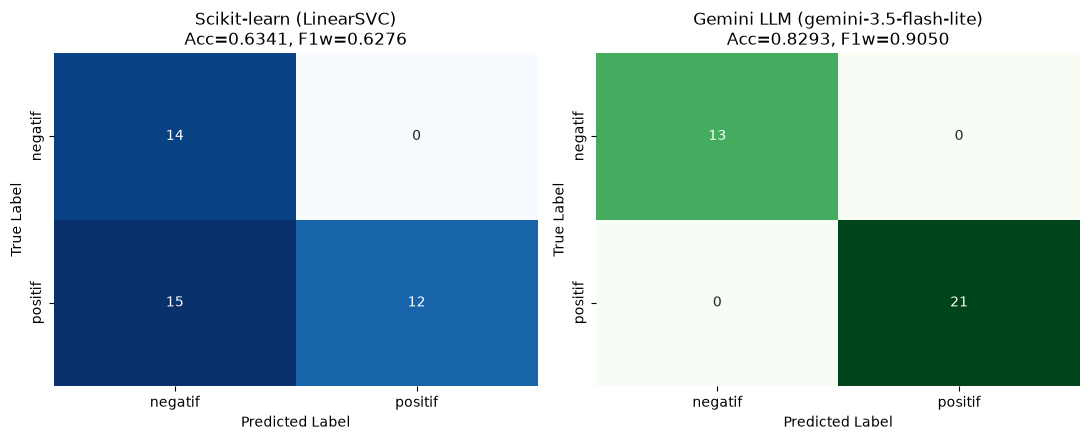


Total test rows misclassified by >=1 model: 18 / 41
                                            review_text  y_true y_pred_classic y_pred_llm
     Kualitas produk sangat memuaskan, akan order lagi. positif        negatif    positif
Produknya rapi dan bersih, tidak ada cacat sama sekali. positif        negatif    positif
Produknya rapi dan bersih, tidak ada cacat sama sekali. positif        negatif    invalid
            Mantap, sesuai gambar dan harga terjangkau. positif        positif    invalid
     Kualitas produk sangat memuaskan, akan order lagi. positif        negatif    invalid
  Pelayanan lambat dan tidak responsif saat dikomplain. negatif        negatif    invalid


In [12]:
summary_df = pd.DataFrame([
    {
        'Pendekatan': f'Scikit-learn ({best_model_name})',
        'Accuracy': round(classic_metrics['accuracy'], 4),
        'Precision': round(classic_metrics['precision_weighted'], 4),
        'Recall': round(classic_metrics['recall_weighted'], 4),
        'F1-Score': round(classic_metrics['f1_weighted'], 4),
        'F1-Macro': round(classic_metrics['f1_macro'], 4),
        'Total Inference (s)': round(classic_infer_time_sec, 6),
        'Avg Latency/Item (ms)': round(classic_latency_ms, 4),
    },
    {
        'Pendekatan': f'Gemini LLM ({GEMINI_MODEL})',
        'Accuracy': round(llm_metrics['accuracy'], 4),
        'Precision': round(llm_metrics['precision_weighted'], 4),
        'Recall': round(llm_metrics['recall_weighted'], 4),
        'F1-Score': round(llm_metrics['f1_weighted'], 4),
        'F1-Macro': round(llm_metrics['f1_macro'], 4),
        'Total Inference (s)': round(llm_total_time_sec, 4),
        'Avg Latency/Item (ms)': round(llm_df['latency_sec'].mean() * 1000, 2),
    },
])

print('=== Tabel Ringkasan Perbandingan (Weighted Average) ===')
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(
    cm_classic, annot=True, fmt='d', cmap='Blues',
    xticklabels=LABELS, yticklabels=LABELS, ax=axes[0], cbar=False
)
axes[0].set_title(f'Scikit-learn ({best_model_name})\nAcc={classic_metrics["accuracy"]:.4f}, F1w={classic_metrics["f1_weighted"]:.4f}')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(
    cm_llm, annot=True, fmt='d', cmap='Greens',
    xticklabels=LABELS, yticklabels=LABELS, ax=axes[1], cbar=False
)
axes[1].set_title(f'Gemini LLM ({GEMINI_MODEL})\nAcc={llm_metrics["accuracy"]:.4f}, F1w={llm_metrics["f1_weighted"]:.4f}')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Error analysis: inspect misclassified samples for both approaches
misclassified = predictions_df[
    (predictions_df['y_true'] != predictions_df['y_pred_classic']) |
    (predictions_df['y_true'] != predictions_df['y_pred_llm'])
]
print(f'\nTotal test rows misclassified by >=1 model: {len(misclassified)} / {len(predictions_df)}')
if len(misclassified) > 0:
    print(misclassified[['review_text', 'y_true', 'y_pred_classic', 'y_pred_llm']].drop_duplicates().to_string(index=False))

## 7. Analisis Trade-off dan Limitation

### 7.1 Performa

| Pendekatan | Accuracy | Precision (Weighted) | Recall (Weighted) | F1-Score (Weighted) | F1-Macro |
|---|---:|---:|---:|---:|---:|
| Scikit-learn (`LinearSVC`) | 0.6341 | 0.8234 | 0.6341 | 0.6276 | 0.6333 |
| Gemini LLM (`gemini-3.5-flash-lite`) | 0.8293 | 1.0000 | 0.8293 | 0.9050 | 0.9190 |

- **Pendekatan unggul & signifikansi selisih**: Gemini LLM unggul signifikan dibanding `LinearSVC` pada seluruh metrik utama (+19.52 poin persentase pada Accuracy dan +27.74 poin pada F1-Score weighted), bahkan ketika 7 dari 41 prediksi Gemini berstatus `invalid` akibat error API.
- **Performa bersyarat pada pemanggilan API sukses**: Dari 34 request Gemini yang berhasil (`status == 'ok'`), akurasinya mencapai **100% (34/34)** tanpa satu pun salah klasifikasi antara `positif` (21/21) dan `negatif` (13/13).
- **Kelas yang paling sering salah & pola confusion matrix**:
  - **Scikit-learn (`LinearSVC`)**: seluruh kesalahan terjadi pada kelas **`positif`** (15 false negative dari 27 sampel `positif`; Recall `positif` = 0.4444, sedangkan Recall `negatif` = 1.0000). Dari inspeksi sampel salah:
    1. *"Produknya rapi dan bersih, tidak ada cacat sama sekali."* (9 baris) diprediksi `negatif` karena mengandung token `tidak` dan `cacat` yang di training set berasosiasi kuat dengan ulasan negatif. TF-IDF bag-of-ngrams gagal memahami negasi ganda (`tidak ada cacat` = positif).
    2. *"Kualitas produk sangat memuaskan, akan order lagi."* (6 baris) diprediksi `negatif` karena frasa `kualitas produk` juga muncul pada ulasan negatif training set sedangkan kata positif spesifiknya kurang terwakili pada 32 teks unik training.
  - **Gemini LLM (`gemini-3.5-flash-lite`)**: tidak ada salah klasifikasi semantik pada confusion matrix valid (`[[13, 0], [0, 21]]`). Seluruh 7 kegagalan (6 `positif`, 1 `negatif`) berasal dari `api_error` (`429 RESOURCE_EXHAUSTED`) pada 7 sampel terakhir (baris indeks 34–40).

### 7.2 Effort Implementasi

| Aspek | Model Klasik (Scikit-learn) | LLM API (Gemini) |
|---|---|---|
| **Preprocessing** | Wajib merancang normalisasi teks, tokenisasi, dan pemilihan n-gram TF-IDF (serta menjaga kata negasi). | Minimal; cukup merancang prompt terstruktur dan normalisasi/validasi output teks. |
| **Training** | Wajib split bebas leakage, cross-validation (`GroupKFold`), seleksi model, dan `fit()` pada data berlabel. | Tidak memerlukan training; langsung pakai (zero-shot). |
| **Konfigurasi Model** | Sederhana & deterministik (`TfidfVectorizer` + `LinearSVC`, `random_state=42`). | Perlu manajemen API key aman, konfigurasi parameter (`temperature=0.0`, `max_output_tokens=10`), retry/backoff, dan parser output. |
| **Maintenance** | Perlu re-training periodik saat muncul kosakata/produk/slang baru (*concept drift*). | Perlu memantau perubahan versi/depresiasi model, kuota rate limit, dan stabilitas format respons. |
| **Kebutuhan Dataset Berlabel** | Tinggi: performa sangat bergantung pada keragaman teks berlabel (32 teks unik terlalu sempit untuk generalisasi TF-IDF). | Rendah untuk inferensi (cukup test set berlabel untuk validasi/benchmarking). |

### 7.3 Kecepatan & Bottleneck Skalabilitas

- **Waktu training model klasik**: **0.0121 detik** (159 sampel, 338 fitur TF-IDF).
- **Waktu inference model klasik**: **0.0045 detik** total untuk 41 sampel (**0.1096 ms/ulasan**).
- **Latency Gemini API**: **70.5785 detik** total untuk 41 sampel sekuensial (**1.7213 detik/request** keseluruhan; **0.9835 detik/request** pada 34 panggilan sukses dan **5.3047 detik/request** pada 7 panggilan gagal akibat 3x retry backoff).
- **Perbandingan & bottleneck**: Inference Gemini ~15.700x lebih lambat dibanding `LinearSVC` lokal. Jika volume ulasan naik menjadi 10.000 ulasan/hari, pemanggilan sekuensial Gemini memakan waktu ~2,7 jam (pada 0.98 s/item) dan langsung terbentur rate limit RPM/RPD, sehingga wajib menggunakan batching/async queue/tier berbayar. Sebaliknya, `LinearSVC` memproses 10.000 ulasan dalam ~1,1 detik secara lokal.

### 7.4 Biaya

- **Penggunaan token terukur (Gemini)**: pada 34 panggilan sukses tercatat **2.340 prompt tokens** (~68.8 token/ulasan) dan **68 output tokens** (2.0 token/ulasan).
- **Proyeksi biaya variabel**: Setiap ulasan baru menimbulkan biaya API per token (prompt + output). Pada skala 100.000–1.000.000 ulasan per bulan, biaya API terus bertambah linear seiring trafik (ditambah overhead retry jika terjadi error).
- **Model klasik (Scikit-learn)**: Setelah selesai dilatih, biaya inferensi per prediksi mendekati **Rp 0 / marginal cost nyaris nol** karena berjalan di CPU lokal/server aplikasi yang sudah ada tanpa biaya API eksternal.

### 7.5 Limitation

**Model Klasik (`LinearSVC` + TF-IDF):**
1. **Keterbatasan generalisasi & sensitivitas negasi**: Gagal menangani frasa negasi ganda (*"tidak ada cacat"*) atau kata baru di luar 32 teks unik training set.
2. **Ketergantungan tinggi pada kualitas & keragaman dataset**: Meski dataset memiliki 200 baris, hanya ada 40 teks unik. Sedikitnya variasi kalimat membatasi representasi bag-of-words/ngrams.
3. **Preprocessing trade-off**: Normalisasi tanda baca membantu konsistensi, tetapi pendekatan leksikal murni tidak menangkap konteks semantik kalimat.

**LLM API (`gemini-3.5-flash-lite`):**
1. **Rate limit & kegagalan API nyata**: Pada eksperimen ini, **7 dari 41 panggilan (17.1%) gagal** dengan `429 RESOURCE_EXHAUSTED` meski sudah memakai exponential backoff 3 percobaan.
2. **Latency & ketergantungan jaringan eksternal**: Rata-rata ~0.98 detik per request sukses membuat pemrosesan sinkron saat page load tidak cocok untuk UI halaman produk.
3. **Biaya operasional berulang & vendor lock-in**: Skala besar membutuhkan tier berbayar dan anggaran token berkelanjutan.
4. **Potensi inkonsistensi output**: Model sempat mengembalikan kapitalisasi/tanda baca (mis. `"Positif."` pada uji awal) sehingga tetap wajib ada fungsi normalisasi defensif.

## 8. Rekomendasi Technical Approach

### Rekomendasi: **Pendekatan Bertahap / Hybrid (Gemini LLM sebagai *Offline Batch/Teacher* -> Model Klasik/Lokal Terlatih untuk Produksi Real-Time)**, dengan **Scikit-learn sebagai target runtime produksi jangka panjang** dan **Gemini API untuk *immediate MVP / asynchronous labeling***.

### Alasan Berbasis Data Eksperimen:
1. **Performa vs Kesiapan Data Saat Ini**: Pada dataset awal yang hanya berisi **40 teks ulasan unik** (32 train / 8 test), `LinearSVC` hanya mencapai Accuracy **0.6341** (F1 weighted **0.6276**) dan gagal pada pola negasi ganda (*"tidak ada cacat"*), sedangkan Gemini mencapai **100% akurasi semantik pada seluruh 34 request sukses** (F1 weighted **0.9050** termasuk penalti 7 error).
2. **Mengapa Tidak Langsung Pakai Gemini Secara Sinkron di Halaman Produk**: Eksperimen membuktikan latency rata-rata ~0.98–1.72 detik/ulasan dan kegagalan **17.1% (`429 RESOURCE_EXHAUSTED`)** pada burst kecil 41 ulasan. Memanggil LLM sinkron per ulasan di sistem produksi e-commerce berisiko memicu bottleneck, kegagalan parsial, dan biaya token linear yang mahal.
3. **Mengapa Tidak Langsung Pakai Model Klasik Tanpa Penambahan Data**: Meskipun super cepat (**0.1096 ms/ulasan**), biaya nol, dan bebas ketergantungan API eksternal, model klasik belum layak produksi jika hanya dilatih di 32 teks unik karena generalisasinya buruk (Recall `positif` hanya 0.4444).

### Rencana Implementasi Konkret untuk Tim Produk:
- **Fase 1 (Jangka Pendek / MVP Asinkron)**: Jalankan Gemini (`gemini-3.5-flash-lite`) dalam **background batch job terjadwal** dengan *rate-limiter* (mis. jeda antar-request / token bucket sesuai RPM, caching berdasarkan hash `review_text` agar teks berulang tidak dipanggil ulang, dan *dead-letter retry queue*). Hasil klasifikasi ulasan disimpan ke database produk sehingga halaman produk membaca label dari DB tanpa latency LLM.
- **Fase 2 (Skalabilitas & Efisiensi Biaya)**: Kumpulkan ribuan variasi ulasan nyata dari Fase 1 (hasil pelabelan Gemini yang diaudit sampelnya oleh tim) untuk memperkaya dataset berlabel yang beragam, lalu latih ulang model lokal (Scikit-learn terkalibrasi / model klasifikasi teks ringan seperti IndoBERT distilled) untuk inferensi real-time berbiaya hampir nol dan bebas risiko rate limit API.